In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, ShuffleSplit, cross_validate
from sklearn.linear_model import LinearRegression, Lasso, LassoCV, Ridge, RidgeCV
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import accuracy_score, mean_squared_error,root_mean_squared_error,r2_score
from sklearn.pipeline import make_pipeline

### Read data

In [3]:
df = pd.read_csv("D:\\Data science\\Assignments\\Questions\\MLR\\MLR\\ToyotaCorolla - MLR.csv")
display(df.head())
display(df.info())
display(df.describe())

,Price,Age_08_04,KM,Fuel_Type,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
0,13500,23,46986,Diesel,90,0,2000,3,4,5,1165
1,13750,23,72937,Diesel,90,0,2000,3,4,5,1165
2,13950,24,41711,Diesel,90,0,2000,3,4,5,1165
3,14950,26,48000,Diesel,90,0,2000,3,4,5,1165
4,13750,30,38500,Diesel,90,0,2000,3,4,5,1170


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Price      1436 non-null   int64 
 1   Age_08_04  1436 non-null   int64 
 2   KM         1436 non-null   int64 
 3   Fuel_Type  1436 non-null   object
 4   HP         1436 non-null   int64 
 5   Automatic  1436 non-null   int64 
 6   cc         1436 non-null   int64 
 7   Doors      1436 non-null   int64 
 8   Cylinders  1436 non-null   int64 
 9   Gears      1436 non-null   int64 
 10  Weight     1436 non-null   int64 
dtypes: int64(10), object(1)
memory usage: 123.5+ KB


None

,Price,Age_08_04,KM,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
count,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.00000,1436.000000,1436.0,1436.000000,1436.00000
mean,10730.824513,55.947075,68533.259749,101.502089,0.055710,1576.85585,4.033426,4.0,5.026462,1072.45961
std,3626.964585,18.599988,37506.448872,14.981080,0.229441,424.38677,0.952677,0.0,0.188510,52.64112
min,4350.000000,1.000000,1.000000,69.000000,0.000000,1300.00000,2.000000,4.0,3.000000,1000.00000
25%,8450.000000,44.000000,43000.000000,90.000000,0.000000,1400.00000,3.000000,4.0,5.000000,1040.00000
50%,9900.000000,61.000000,63389.500000,110.000000,0.000000,1600.00000,4.000000,4.0,5.000000,1070.00000
75%,11950.000000,70.000000,87020.750000,110.000000,0.000000,1600.00000,5.000000,4.0,5.000000,1085.00000
max,32500.000000,80.000000,243000.000000,192.000000,1.000000,16000.00000,5.000000,4.0,6.000000,1615.00000


### EDA

In [4]:
df.isnull().sum()

Price        0
Age_08_04    0
KM           0
Fuel_Type    0
HP           0
Automatic    0
cc           0
Doors        0
Cylinders    0
Gears        0
Weight       0
dtype: int64

No null values

In [5]:
df.describe()

,Price,Age_08_04,KM,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
count,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.00000,1436.000000,1436.0,1436.000000,1436.00000
mean,10730.824513,55.947075,68533.259749,101.502089,0.055710,1576.85585,4.033426,4.0,5.026462,1072.45961
std,3626.964585,18.599988,37506.448872,14.981080,0.229441,424.38677,0.952677,0.0,0.188510,52.64112
min,4350.000000,1.000000,1.000000,69.000000,0.000000,1300.00000,2.000000,4.0,3.000000,1000.00000
25%,8450.000000,44.000000,43000.000000,90.000000,0.000000,1400.00000,3.000000,4.0,5.000000,1040.00000
50%,9900.000000,61.000000,63389.500000,110.000000,0.000000,1600.00000,4.000000,4.0,5.000000,1070.00000
75%,11950.000000,70.000000,87020.750000,110.000000,0.000000,1600.00000,5.000000,4.0,5.000000,1085.00000
max,32500.000000,80.000000,243000.000000,192.000000,1.000000,16000.00000,5.000000,4.0,6.000000,1615.00000


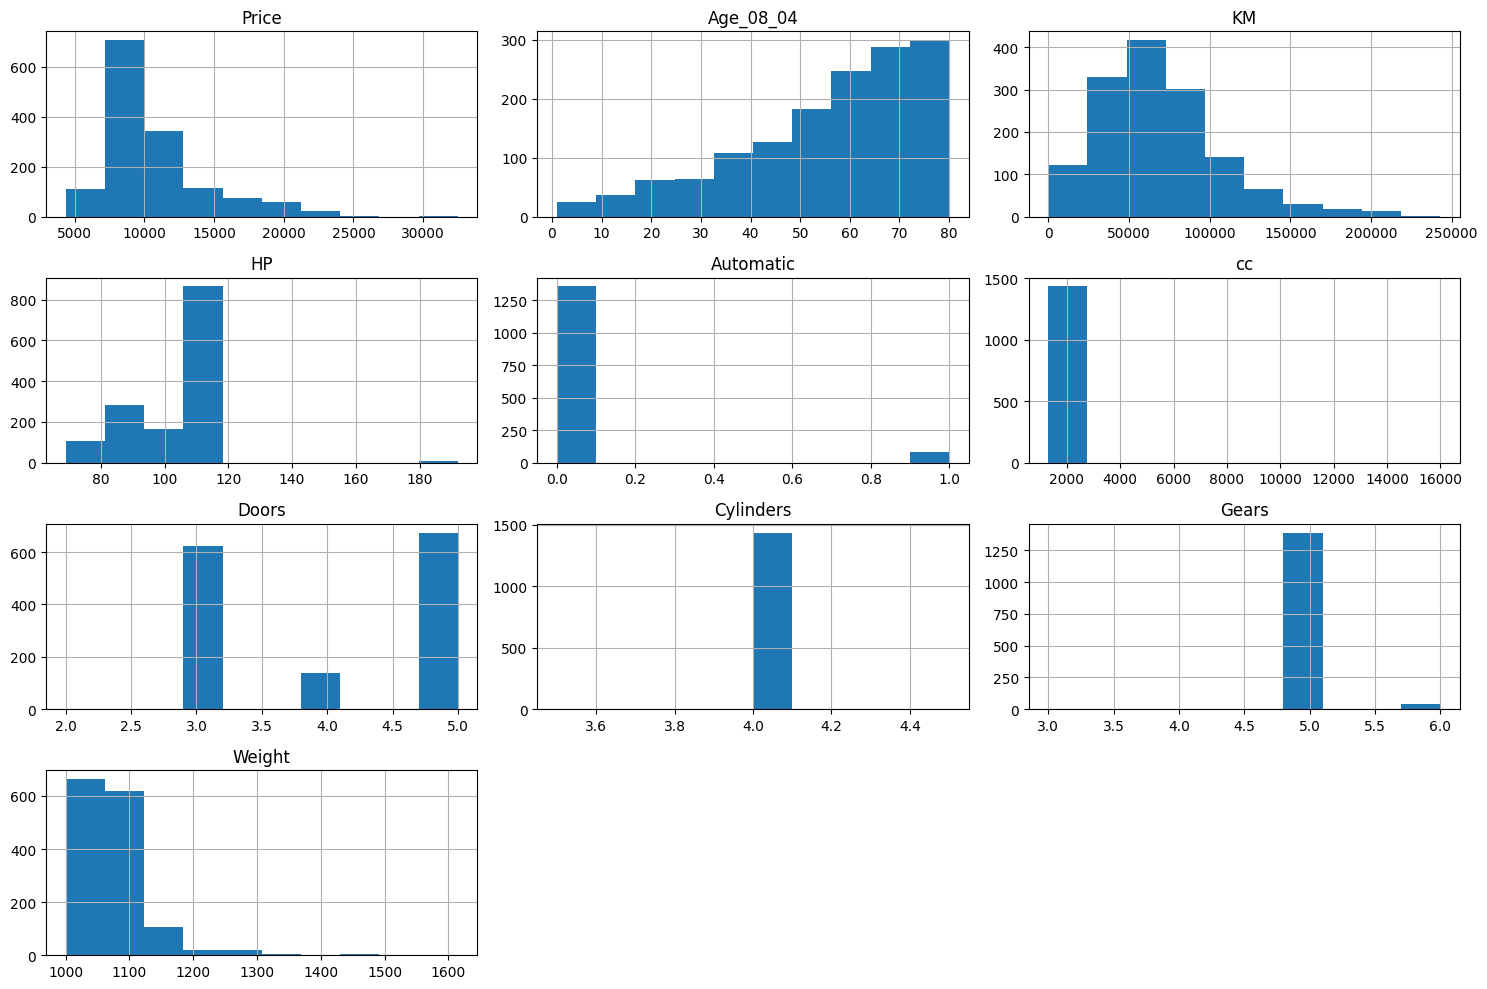

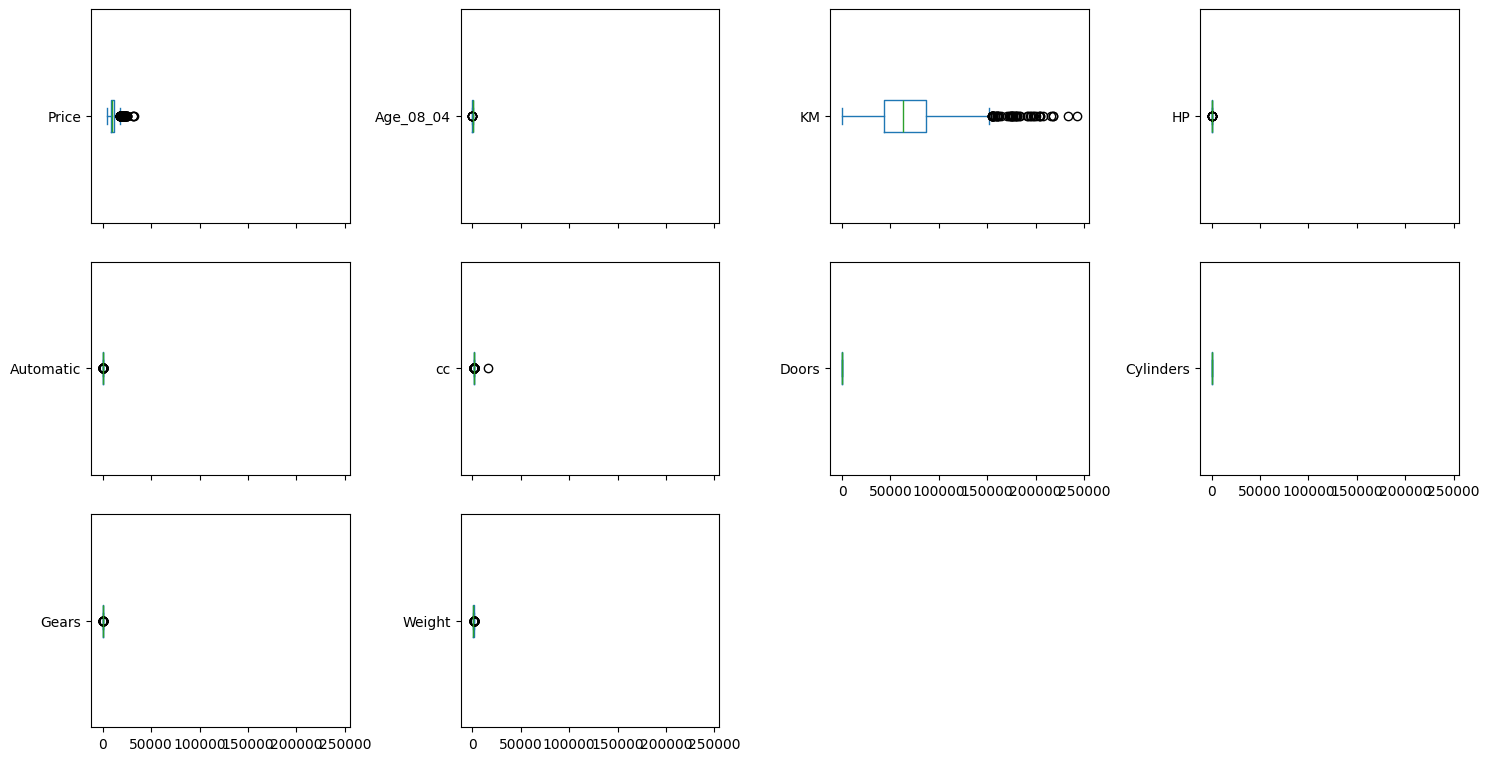

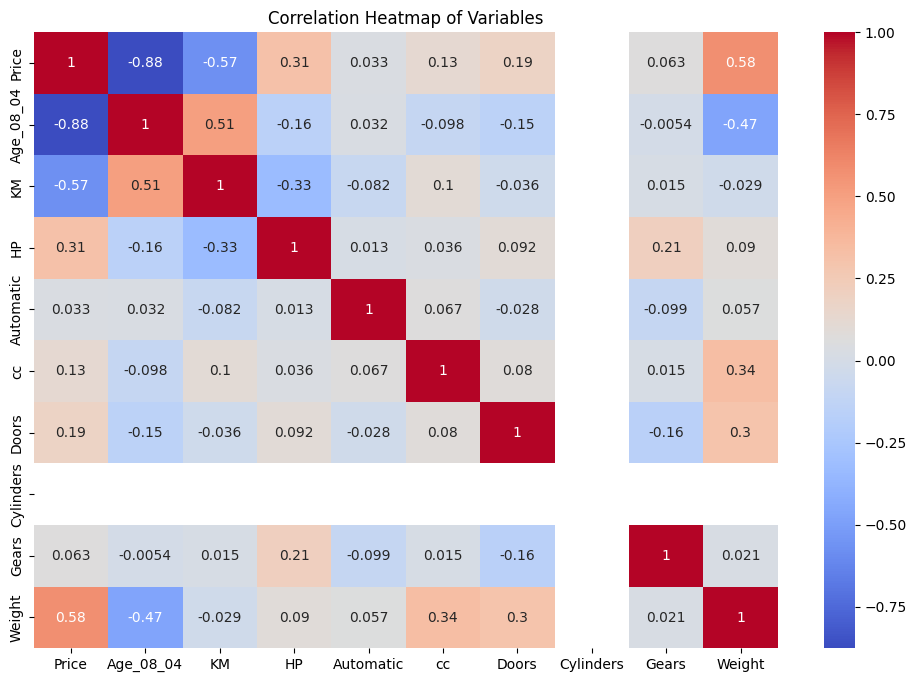

In [6]:
# histograms for numerical variables
df.hist(figsize=(15, 10))
plt.tight_layout()
plt.show()

# Create boxplots for numerical variables
df.plot(kind='box', subplots=True, layout=(4, 4), figsize=(15, 10), vert = False)
plt.tight_layout()
plt.show()

# Generate a correlation heatmap
plt.figure(figsize=(12, 8))
correlation_matrix = df.corr(numeric_only=True)
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap of Variables')
plt.show()


### label encoding

In [8]:
LE = LabelEncoder()
df['Fuel_Type'] = LE.fit_transform(df['Fuel_Type'])
df.head()

,Price,Age_08_04,KM,Fuel_Type,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
0,13500,23,46986,1,90,0,2000,3,4,5,1165
1,13750,23,72937,1,90,0,2000,3,4,5,1165
2,13950,24,41711,1,90,0,2000,3,4,5,1165
3,14950,26,48000,1,90,0,2000,3,4,5,1165
4,13750,30,38500,1,90,0,2000,3,4,5,1170


### Standerdization and normalization

In [9]:
SS = StandardScaler()
df[df.columns[[1,2,4,6,7,9,10]]] = SS.fit_transform(df[df.columns[[1,2,4,6,7,9,10]]])

In [10]:
SN = MinMaxScaler()
df[df.columns[[1,2,4,6,7,9,10]]] = SN.fit_transform(df[df.columns[[1,2,4,6,7,9,10]]])

In [11]:
df.head()

,Price,Age_08_04,KM,Fuel_Type,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
0,13500,0.278481,0.193355,1,0.170732,0,0.047619,0.333333,4,0.666667,0.268293
1,13750,0.278481,0.300149,1,0.170732,0,0.047619,0.333333,4,0.666667,0.268293
2,13950,0.291139,0.171647,1,0.170732,0,0.047619,0.333333,4,0.666667,0.268293
3,14950,0.316456,0.197528,1,0.170732,0,0.047619,0.333333,4,0.666667,0.268293
4,13750,0.367089,0.158433,1,0.170732,0,0.047619,0.333333,4,0.666667,0.276423


### Data Partitioning

In [12]:
X = df.drop('Price', axis = 1)
Y = df['Price']

In [13]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.2, random_state=42)

In [14]:
print("\nShape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", Y_train.shape)
print("Shape of y_test:", Y_test.shape)



Shape of X_train: (1148, 10)
Shape of X_test: (288, 10)
Shape of y_train: (1148,)
Shape of y_test: (288,)


### Model one fitting (linear Regression)

In [44]:
model = LinearRegression()
model.fit(X_train, Y_train)
Y_pred_train = model.predict(X_train)
Y_pred_test = model.predict(X_test)

### Evaluate model one

In [45]:
r2 = r2_score(Y_test, Y_pred_test)
rmse = root_mean_squared_error(Y_test, Y_pred_test)
print("R Square:", np.round(r2,3)*100,"%")
print("RMSE:", np.round(rmse,2))

R Square: 84.3 %
RMSE: 1448.05


In [46]:
print(f"Intercet: {model.intercept_}")
Coefficients = model.coef_
print("\nModel Cofficients")
print(pd.Series(Coefficients, index=X_train.columns))

Intercet: 13601.049648783637

Model Cofficients
Age_08_04   -9.593463e+03
KM          -4.115333e+03
Fuel_Type    8.620564e+02
HP           2.540969e+03
Automatic    2.451969e+02
cc          -1.080676e+03
Doors       -1.088389e+02
Cylinders   -9.947598e-13
Gears        1.590846e+03
Weight       1.445905e+04
dtype: float64


### Model two fitting (support vector Regressor)

In [47]:
model = SVR(kernel='poly', degree=3)
model.fit(X_train, Y_train)
Y_pred_train = model.predict(X_train)
Y_pred_test = model.predict(X_test)

### Evaluate model two

In [48]:
r2 = r2_score(Y_test, Y_pred_test)
rmse = root_mean_squared_error(Y_test, Y_pred_test)
print("R Square:", np.round(r2,3)*100,"%")
print("RMSE:", np.round(rmse,2))

R Square: -2.7 %
RMSE: 3701.75


### Model three fitting (KNN regressor)

In [49]:
model = KNeighborsRegressor(n_neighbors=5)
model.fit(X_train, Y_train)
Y_pred_train = model.predict(X_train)
Y_pred_test = model.predict(X_test)


### Evaluate model three

In [50]:
r2 = r2_score(Y_test, Y_pred_test)
rmse = root_mean_squared_error(Y_test, Y_pred_test)
print("R Square:", np.round(r2,3)*100,"%")
print("RMSE:", np.round(rmse,2))

R Square: 90.2 %
RMSE: 1142.0


### cross validation

In [51]:
shuffle_split = ShuffleSplit(n_splits=100, test_size = 0.2)
cv_scores = cross_validate(model, X, Y, cv=shuffle_split, scoring='r2', return_train_score=True)
train_scores = cv_scores["train_score"]
test_scores = cv_scores["test_score"]

print("CV Training score",np.round(train_scores.mean(),2))
print("CV Test score",np.round(test_scores.mean(),2))

CV Training score 0.92
CV Test score 0.88


### Lesso and Ridge

In [52]:
lasso_cv_pipeline = make_pipeline(StandardScaler(), LassoCV(cv=5, max_iter=10000, alphas=None))
lasso_cv_pipeline.fit(X_train, Y_train)

c:\Users\abhir\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1641: FutureWarning: 'alphas=None' is deprecated and will be removed in 1.9, at which point the default value will be set to 100. Set 'alphas=100' to silence this warning.
  warnings.warn(


,steps,"[('standardscaler', ...), ('lassocv', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,eps,0.001
,n_alphas,'deprecated'
,alphas,None
,fit_intercept,True


In [53]:
print("All alphas tried by lassoCV:",lasso_cv_pipeline.named_steps['lassocv'].alphas_)

All alphas tried by lassoCV: [3177.72306199 2963.55516308 2763.82146376 2577.54914729 2403.83096152
 2241.82080005 2090.72958124 1949.82140489 1818.40996803 1695.85522219
 1581.56025604 1474.96838808 1375.56045527 1282.85228443 1196.39233401
 1115.75949489 1040.56103925  970.43070784  905.02692605  844.03114025
  787.14626627  734.09524241  684.61968001  638.47860492  595.44728386
  555.31612982  517.88968125  482.98565005  450.43403373  420.07628741
  391.76455158  365.360932    340.736828    317.7723062   296.35551631
  276.38214638  257.75491473  240.38309615  224.18208001  209.07295812
  194.98214049  181.8409968   169.58552222  158.1560256   147.49683881
  137.55604553  128.28522844  119.6392334   111.57594949  104.05610392
   97.04307078   90.5026926    84.40311403   78.71462663   73.40952424
   68.461968     63.84786049   59.54472839   55.53161298   51.78896812
   48.298565     45.04340337   42.00762874   39.17645516   36.5360932
   34.0736828    31.77723062   29.63555163   27.6

In [54]:
#extract best alpha
best_alpha = lasso_cv_pipeline.named_steps['lassocv'].alpha_
print('Best alpha from LassoCV:',best_alpha)

Best alpha from LassoCV: 36.536093199562906


In [55]:
Y_train_lasso = lasso_cv_pipeline.predict(X_train)
Y_test_lasso = lasso_cv_pipeline.predict(X_test)
print("LassoCV Train R2:",np.round(r2_score(Y_train, Y_train_lasso)*100,2))
print("Lasso Test R2:",np.round(r2_score(Y_test,Y_test_lasso)*100,2))

LassoCV Train R2: 86.88
Lasso Test R2: 84.56


In [56]:
mse_path = lasso_cv_pipeline.named_steps['lassocv'].mse_path_.mean(axis=1)
alphas_tested = lasso_cv_pipeline.named_steps['lassocv'].alphas_
alphas_tested

array([3177.72306199, 2963.55516308, 2763.82146376, 2577.54914729,
       2403.83096152, 2241.82080005, 2090.72958124, 1949.82140489,
       1818.40996803, 1695.85522219, 1581.56025604, 1474.96838808,
       1375.56045527, 1282.85228443, 1196.39233401, 1115.75949489,
       1040.56103925,  970.43070784,  905.02692605,  844.03114025,
        787.14626627,  734.09524241,  684.61968001,  638.47860492,
        595.44728386,  555.31612982,  517.88968125,  482.98565005,
        450.43403373,  420.07628741,  391.76455158,  365.360932  ,
        340.736828  ,  317.7723062 ,  296.35551631,  276.38214638,
        257.75491473,  240.38309615,  224.18208001,  209.07295812,
        194.98214049,  181.8409968 ,  169.58552222,  158.1560256 ,
        147.49683881,  137.55604553,  128.28522844,  119.6392334 ,
        111.57594949,  104.05610392,   97.04307078,   90.5026926 ,
         84.40311403,   78.71462663,   73.40952424,   68.461968  ,
         63.84786049,   59.54472839,   55.53161298,   51.78896

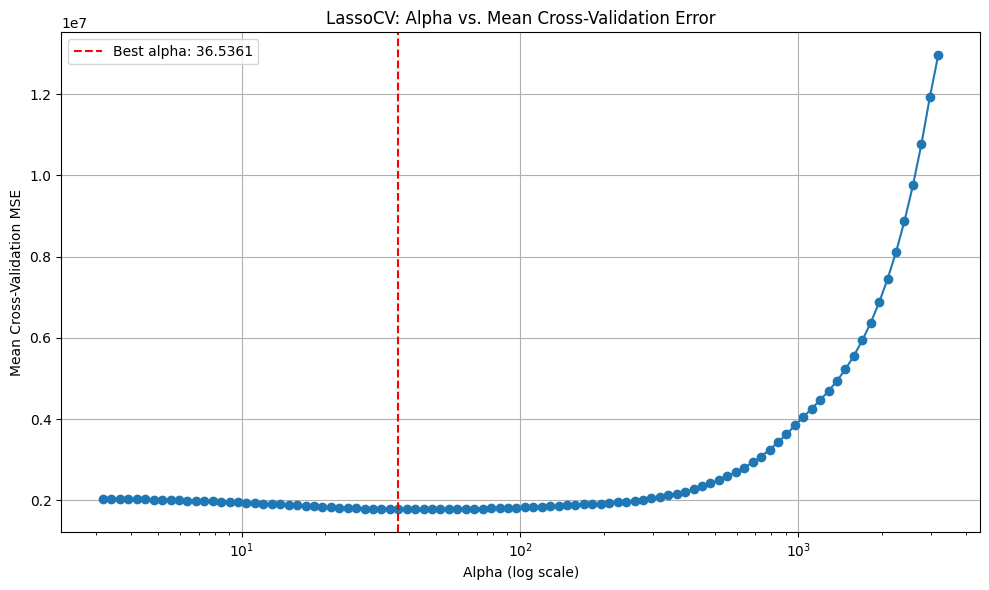

In [57]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(alphas_tested, mse_path, marker='o')
plt.axvline(best_alpha, color='red', linestyle='--', label=f'Best alpha: {best_alpha:.4f}')
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('Mean Cross-Validation MSE')
plt.title('LassoCV: Alpha vs. Mean Cross-Validation Error')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [58]:
lasso_model = lasso_cv_pipeline.named_steps['lassocv']
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lasso_model.coef_
})
zeroed_features = coef_df[coef_df['Coefficient'] == 0]
print("Number of features removed by LassoCV:", len(zeroed_features))


Number of features removed by LassoCV: 3


In [59]:
# Step 10: Test with higher alpha to simplify model
for alpha_val in range(10,200):
    lasso_custom = make_pipeline(StandardScaler(), Lasso(alpha=alpha_val, max_iter=10000))
    lasso_custom.fit(X_train, Y_train)

    Y_test_pred = lasso_custom.predict(X_test)
    r2_test = r2_score(Y_test, Y_test_pred)
    non_zero_count = sum(lasso_custom.named_steps['lasso'].coef_ != 0)

    print(f"\nAlpha: {alpha_val}")
    print(f"Test R²: {r2_test:.4f}")
    print(f"Retained Features: {non_zero_count}")


Alpha: 10
Test R²: 0.8438
Retained Features: 9

Alpha: 11
Test R²: 0.8439
Retained Features: 9

Alpha: 12
Test R²: 0.8440
Retained Features: 9

Alpha: 13
Test R²: 0.8441
Retained Features: 9

Alpha: 14
Test R²: 0.8441
Retained Features: 9

Alpha: 15
Test R²: 0.8442
Retained Features: 9

Alpha: 16
Test R²: 0.8443
Retained Features: 9

Alpha: 17
Test R²: 0.8444
Retained Features: 9

Alpha: 18
Test R²: 0.8445
Retained Features: 9

Alpha: 19
Test R²: 0.8445
Retained Features: 9

Alpha: 20
Test R²: 0.8446
Retained Features: 9

Alpha: 21
Test R²: 0.8447
Retained Features: 9

Alpha: 22
Test R²: 0.8448
Retained Features: 9

Alpha: 23
Test R²: 0.8448
Retained Features: 8

Alpha: 24
Test R²: 0.8449
Retained Features: 7

Alpha: 25
Test R²: 0.8450
Retained Features: 7

Alpha: 26
Test R²: 0.8450
Retained Features: 7

Alpha: 27
Test R²: 0.8451
Retained Features: 7

Alpha: 28
Test R²: 0.8451
Retained Features: 7

Alpha: 29
Test R²: 0.8452
Retained Features: 7

Alpha: 30
Test R²: 0.8453
Retained Feat

for alpha 169 we are getting best r2 and low retained features

In [60]:
final_alpha = 169
final_lasso = make_pipeline(StandardScaler(), Lasso(alpha=final_alpha, max_iter=10000))
final_lasso.fit(X_train, Y_train)

final_coef = final_lasso.named_steps['lasso'].coef_
selected_features = X.columns[final_coef != 0]
print("\nFinal Selected Features (alpha = 165):", len(selected_features))


Final Selected Features (alpha = 165): 4


In [61]:
# Final evaluation
y_train_final = final_lasso.predict(X_train)
y_test_final = final_lasso.predict(X_test)

print("Final Lasso Train R²:", np.round(r2_score(Y_train, Y_train_lasso)*100,2))
print("Final Lasso Test R² :", np.round(r2_score(Y_test, Y_test_lasso)*100,2))

Final Lasso Train R²: 86.88
Final Lasso Test R² : 84.56


In [62]:
selected_features

Index(['Age_08_04', 'KM', 'HP', 'Weight'], dtype='object')

In [63]:
df.columns

Index(['Price', 'Age_08_04', 'KM', 'Fuel_Type', 'HP', 'Automatic', 'cc',
       'Doors', 'Cylinders', 'Gears', 'Weight'],
      dtype='object')

### Interview questions

##### 1.What is Normalization & Standardization and how is it helpful?

just like lableencoader and one hot encodar transformations for descrete data, we have normalization and standerdization transformations for continuous data  
1. Normalization: converts the data into data between range of 0 to +1
2. Standerdization: converts the data into data between range of -3 to +3  
  
both techniques are used to remove units for model fitting

##### 2.What techniques can be used to address multicollinearity in multiple linear regression?

Here are techniques to address this issue:

1. Correlation Analysis and Variable Selection:

2. Variance Inflation Factor (VIF):

3. Principal Component Analysis (PCA):

4. Regularization Techniques:

5. Data Collection Strategies:

